# What three years of startup hiring posts say

**Question:** How are tech companies changing the way they hire, judging by Hacker News'
monthly *"Who is hiring?"* thread from November 2023 to September 2026, and how far can that
thread be trusted as a read on the wider market?

**Short answer**

1. **Pay transparency is becoming normal.** Posts listing a salary went from about 1 in 8
   to nearly 1 in 3.
2. **Remote work is shrinking, slowly.** Remote-friendly posts fell from 65% to 53% (yearly
   averages) while onsite-only posts grew by half.
3. **LLM experience is the fastest-growing ask.** Mentions nearly doubled, to 16% of posts.
4. **This thread is not the whole market.** Official job openings in the Information sector
   fell 35% over the same period; HN post volume fell 6%. Read these trends as a view of
   startup and engineering hiring.

**Data:** about 11,500 posts plus BLS JOLTS openings, from the project's published, tested
data. All numbers below come from the SQL in each section (DuckDB), so the notebook reruns
anywhere without warehouse access.


In [1]:
import json
import urllib.request

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

# Published data: the daily refresh writes these files only after every data test passes.
BASE = "https://github.com/wacsvn/hiring-market-pulse/releases/download/data-latest"
TABLES = ["mart_monthly_summary", "mart_tech_trends", "mart_hn_vs_jolts", "mart_salary_bands"]

db = duckdb.connect()
for name in TABLES:
    db.register(name, pd.read_parquet(f"{BASE}/{name}.parquet"))
with urllib.request.urlopen(f"{BASE}/metadata.json") as r:
    meta = json.load(r)

sql = lambda q: db.sql(q).df()  # noqa: E731

BLUE, ORANGE, AQUA, RED, INK = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#52514e"
plt.rcParams.update({
    "figure.figsize": (9, 3.6), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "font.size": 11,
})
print(f"Data published {meta['exported_at'][:10]}; "
      f"{meta['dbt']['tests_passed']} of {meta['dbt']['tests_total']} data checks passed.")

Data published 2026-10-22; 51 of 52 data checks passed.


## 1. Pay transparency is becoming normal

Share of posts that state a salary or hourly rate. Shares are weighted by each month's
post count, so busy months count more than quiet ones.

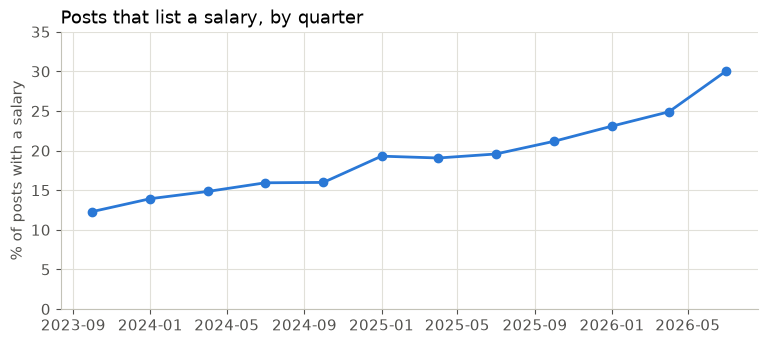

,quarter,share_with_salary,median_salary_usd,posts_with_salary
0,2023-10-01,0.123,160000.0,73.0
1,2024-01-01,0.139,164000.0,107.0
2,2024-04-01,0.148,160000.0,125.0
3,2024-07-01,0.159,169000.0,136.0
4,2024-10-01,0.160,166000.0,127.0
5,2025-01-01,0.193,179000.0,164.0
6,2025-04-01,0.191,178000.0,156.0
7,2025-07-01,0.196,180000.0,157.0
8,2025-10-01,0.212,181000.0,199.0
9,2026-01-01,0.231,190000.0,189.0


In [2]:
salary = sql('''
    select date_trunc('quarter', thread_month)                       as quarter,
           sum(share_with_salary * postings) / sum(postings)         as share_with_salary,
           -- Quarterly figure = average of monthly medians, weighted by how many posts
           -- each month's median is based on (the exact median needs post-level data).
           sum(median_salary_usd * salary_sample_size)
             / sum(salary_sample_size)                                as median_salary_usd,
           sum(salary_sample_size)                                    as posts_with_salary
    from mart_monthly_summary
    where is_complete_month
    group by 1
    order by 1
''')

fig, ax = plt.subplots()
ax.plot(salary["quarter"], salary["share_with_salary"] * 100, color=BLUE, lw=2, marker="o")
ax.set_ylabel("% of posts with a salary")
ax.set_ylim(0, 35)
ax.set_title("Posts that list a salary, by quarter", loc="left")
plt.show()
salary.round({"share_with_salary": 3, "median_salary_usd": -3})

**What it shows.** About 12% of posts listed pay in late 2023. By Q3 2026 it was 30%, and
the rise is steady rather than a one-time jump. Over the same period the typical posted salary
moved from about \$160k to about \$188k.

**Why it matters for a recruiting team.** Once competitors publish ranges, candidates arrive
with a number in mind, and posted ranges become usable benchmarking data.

**Caveat and next step.** Several U.S. states require ranges in job ads, so part of this is
compliance. Splitting the trend by location would show whether companies outside those states
are following too. The salary level is for USD annual ranges only, and those come mostly
from high-pay markets.

## 2. Remote work is shrinking, slowly

"Remote-friendly" means at least one role in the post can be done remotely, including remote
limited to certain countries. Posts that don't say are excluded, so shares don't add up to 100%.

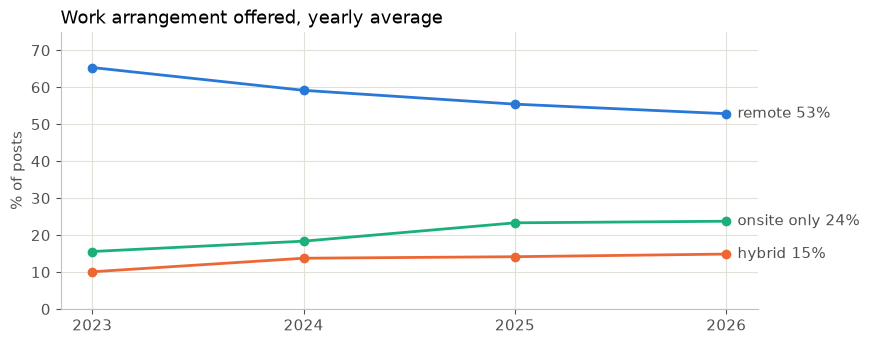

,year,months_of_data,remote,hybrid,onsite_only
0,2023,2,0.653,0.101,0.156
1,2024,12,0.592,0.137,0.184
2,2025,12,0.554,0.141,0.233
3,2026,9,0.528,0.149,0.237


In [3]:
work = sql('''
    select year(thread_month)                                  as year,
           count(*)                                            as months_of_data,
           sum(share_remote * postings) / sum(postings)        as remote,
           sum(share_hybrid * postings) / sum(postings)        as hybrid,
           sum(share_onsite * postings) / sum(postings)        as onsite_only
    from mart_monthly_summary
    where is_complete_month
    group by 1
    order by 1
''')

fig, ax = plt.subplots()
for col, color in [("remote", BLUE), ("hybrid", ORANGE), ("onsite_only", AQUA)]:
    ax.plot(work["year"], work[col] * 100, color=color, lw=2, marker="o")
    ax.annotate(f"{col.replace('_', ' ')} {work[col].iloc[-1]:.0%}",
                (work["year"].iloc[-1], work[col].iloc[-1] * 100),
                xytext=(8, 0), textcoords="offset points", va="center", color=INK)
ax.set_xticks(work["year"])
ax.set_ylabel("% of posts")
ax.set_ylim(0, 75)
ax.set_title("Work arrangement offered, yearly average", loc="left")
plt.show()
work.round(3)

**What it shows.** Remote-friendly posts fell from 65% (late 2023) to 53% (2026 so far).
Onsite-only grew from 16% to 24%; hybrid grew a little. 2023 covers only two months and 2026
nine, so the end years are less certain than the middle.

**Why it matters.** A team hiring onsite is competing with fewer remote offers than two years
ago. But remote is still the majority position among these startups, so it remains a strong
draw for candidates.

## 3. LLM experience is the fastest-growing ask

Average share of posts mentioning each technology in the first six months of the data
(Nov 2023 – Apr 2024) compared with the last six complete months (Apr – Sep 2026).

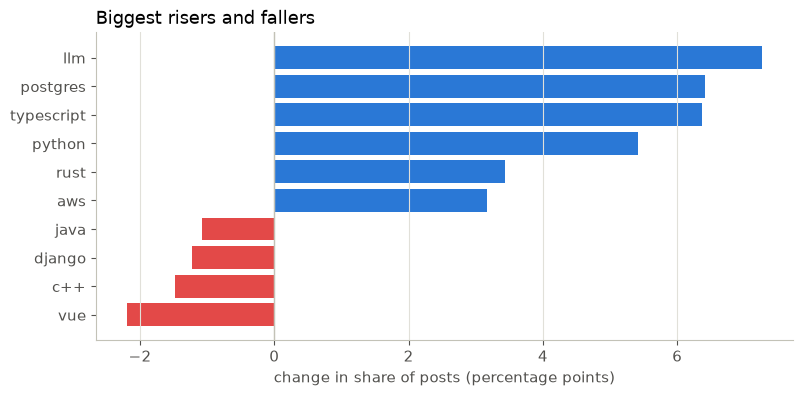

,tech,early,recent,change_pts
0,llm,0.084,0.157,7.255
1,postgres,0.118,0.182,6.416
2,typescript,0.173,0.237,6.371
3,python,0.207,0.262,5.421
4,rust,0.053,0.087,3.438
5,aws,0.124,0.155,3.170
6,javascript,0.131,0.153,2.260
7,node,0.075,0.096,2.092


In [4]:
tech = sql('''
    with windows as (
        select tech,
               avg(share_of_postings) filter (where thread_month <  date '2024-05-01') as early,
               avg(share_of_postings) filter (where thread_month between date '2026-04-01'
                                                                 and date '2026-09-01') as recent
        from mart_tech_trends
        group by tech
    )
    select tech, early, recent, 100 * (recent - early) as change_pts
    from windows
    order by change_pts desc
''')

shown = pd.concat([tech.head(6), tech.tail(4)]).sort_values("change_pts")
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(shown["tech"], shown["change_pts"],
        color=[BLUE if v >= 0 else RED for v in shown["change_pts"]])
ax.axvline(0, color="#c3c2b7", lw=1)
ax.set_xlabel("change in share of posts (percentage points)")
ax.set_title("Biggest risers and fallers", loc="left")
ax.grid(axis="y", visible=False)
plt.show()
tech.round(3).head(8)

**What it shows.** LLM / generative-AI mentions went from 8% to 16% of posts. Postgres,
TypeScript and Python each gained about 5–6 points; Vue, C++ and Django lost ground.

**Why it matters.** For recruiting, this is a signal about where candidate demand is moving:
roles asking for LLM experience now compete with a much larger share of the market than two
years ago. The list only covers the 28 technologies the rules recognise, so new tools won't
show up until they're added.

## 4. This thread is not the whole market

Compare HN post volume with official job openings in the Information sector (BLS JOLTS,
seasonally adjusted), on the months both cover.

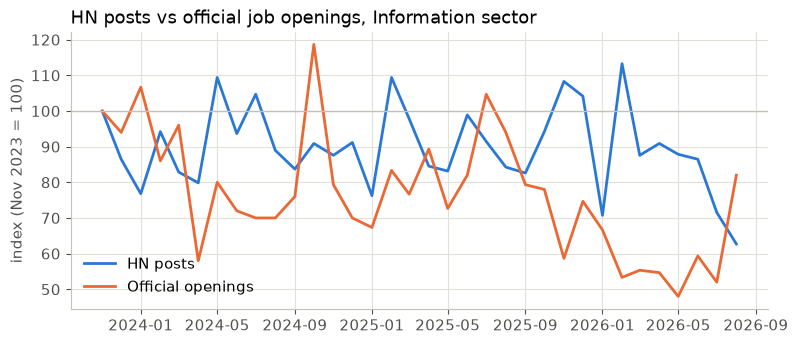

,hn_change_pct,official_change_pct,correlation_of_levels
0,-6.37,-35.02,-0.03


In [5]:
bench = sql('''
    select month, hn_postings, jolts_openings_k,
           100 * hn_postings      / first_value(hn_postings)      over (order by month) as hn_index,
           100 * jolts_openings_k / first_value(jolts_openings_k) over (order by month) as jolts_index
    from mart_hn_vs_jolts
    order by month
''')
summary = sql('''
    with b as (select min(month) as lo, max(month) as hi from mart_hn_vs_jolts)
    select
      100 * (avg(hn_postings)      filter (where month > (select hi from b) - interval 6 month)
           / avg(hn_postings)      filter (where month < (select lo from b) + interval 6 month) - 1)
        as hn_change_pct,
      100 * (avg(jolts_openings_k) filter (where month > (select hi from b) - interval 6 month)
           / avg(jolts_openings_k) filter (where month < (select lo from b) + interval 6 month) - 1)
        as official_change_pct,
      corr(hn_postings, jolts_openings_k) as correlation_of_levels
    from mart_hn_vs_jolts
''')

fig, ax = plt.subplots()
ax.plot(bench["month"], bench["hn_index"], color=BLUE, lw=2, label="HN posts")
ax.plot(bench["month"], bench["jolts_index"], color=ORANGE, lw=2, label="Official openings")
ax.axhline(100, color="#c3c2b7", lw=1)
ax.set_ylabel("index (Nov 2023 = 100)")
ax.legend(frameon=False, loc="lower left")
ax.set_title("HN posts vs official job openings, Information sector", loc="left")
plt.show()
summary.round(2)

**What it shows.** Official openings fell 35% (first six months vs last six); HN posts fell
6%. The two hardly move together (correlation of monthly levels near zero).

**Why it matters.** The earlier findings describe companies that post on HN: startups and
engineering teams, mostly in U.S. tech hubs. They're useful as a view of that corner of the
market, but they shouldn't be read as national hiring trends. If a stakeholder asked "is tech
hiring recovering?", this thread alone couldn't answer it.

## 5. Posted salaries by role and level (last 12 months)

Groups with at least 20 posts that list a USD annual salary. Each value is the midpoint of the
posted range, so these describe what companies advertise, not what people are paid.

In [6]:
sql('''
    select primary_role_family as role, seniority, sample_size as posts,
           p25_usd, median_usd, p75_usd
    from mart_salary_bands
    where is_reliable
    order by median_usd desc
''')

,role,seniority,posts,p25_usd,median_usd,p75_usd
0,other,unknown,21,175000.0,225000.0,245000.0
1,engineering,staff_plus,78,180000.0,200000.0,235500.0
2,engineering,lead_manager,52,162500.0,197500.0,215000.0
3,data_ml,senior,29,176000.0,190000.0,205000.0
4,data_ml,unknown,55,165000.0,185000.0,220000.0
5,engineering,senior,206,155000.0,182300.0,200000.0
6,engineering,unknown,258,145000.0,180000.0,205000.0


Staff-level and lead/manager engineering roles post the highest ranges (medians around
\$200k). Senior engineering roles sit around \$182k (206 posts), just above engineering
posts that don't state a level. The "other /
unknown" group is small and mixed, so its high median shouldn't be read into.

## How much to trust these numbers

In [7]:
acc = meta.get("extractor_accuracy", {})
print(f"Data checks on the last refresh: {meta['dbt']['tests_passed']} passed, "
      f"{meta['dbt']['tests_warned']} flagged, {meta['dbt']['tests_failed']} failed.")
print(f"Field extraction checked against {acc.get('job_posts_checked')} hand-labeled posts:")
pd.Series(acc.get("fields", {}), name="accuracy").map("{:.0%}".format).to_frame()

Data checks on the last refresh: 51 passed, 1 flagged, 0 failed.
Field extraction checked against 46 hand-labeled posts:


,accuracy
Work mode (remote / hybrid / onsite),98%
"Salary found when present, absent when not",98%
Salary values correct,93%
Seniority,91%
Role families exactly right,70%


- Work mode and salary detection are read correctly about 98% of the time, so findings 1
  and 2 rest on solid ground. Role families are the weakest field (about 70%), which is why
  this memo doesn't make claims about role mix.
- About 8% of posts in the thread aren't job ads (replies, links). They are still counted,
  which slightly inflates post volume but barely moves the shares.
- Every number here comes from data that passed the pipeline's automated checks before it was
  published.

## What I'd look at next

1. **Split pay transparency by location** to separate legal compliance from a broader shift.
2. **Track the gap between posted ranges and accepted offers** if internal offer data were
   available. Posted ranges alone can't show what candidates actually take.
3. **Add a second market source** (for example, a broad job-board index) so trends can be
   checked against more than one benchmark before they reach a stakeholder.
